# CIFAR-10 geometry with the MNIST multiscale NFlow architecture

This notebook transplants `MultiLevelImageTransform` and `SimpleMultiLevelImageTransform`
from `mnist_multi_ellipsoid_starflow.ipynb` into the experiment in
`cifar10_additive_nflow.ipynb`. The two transform classes below are copied unchanged.
The input and standard-normal base are changed to **3 x 32 x 32**.

## Architecture and configuration
Each scale squeezes spatial dimensions, applies ActNorm, invertible 1x1 convolutions,
linear parity convolutions and simple tanh parity transforms, and splits channels.
The multilevel transform repacks the latent into image shape, as in the MNIST notebook.
The MNIST notebook reads its hyperparameters from `configs/mnist.yaml`, which was not
attached. Editable settings below therefore use the transform constructor defaults:
kernel size 3, hidden channels 64, three flow steps per scale, three scales.
For CIFAR these scales operate on (12,16,16), (24,8,8), and (48,4,4).
Set these settings to your MNIST YAML values to reproduce its exact configuration.

## Preserved CIFAR experiment
- RGB normalization to [-1,1], seed 31, 80/20 split of the official training partition,
  training/analysis batch sizes 128, no augmentation or dequantization.
- Adam learning rate 0.001, 100 epochs, sample-weighted training NLL checkpoint selection,
  resumable training and best-checkpoint analysis.
- Sampling, pullback geodesics and barycentre, rank-20 tangent-space PGA,
  isometrized geodesics and PGA (five intervals), Euclidean baseline and RMSE comparisons.
- All low-rank solvers retain the original shared pullback barycentre as base point;
  the Euclidean baseline is not recentered PCA.
- CIFAR precision is retained (float32), rather than adopting MNIST's global float64.
  No latent-space star, ellipsoid, or archetypal-mapping stages are imported.

## Execution
Run top to bottom in the original project environment with its `src` package,
PyTorch, torchvision, nflows, NumPy, matplotlib and tqdm. CIFAR-10 downloads through
torchvision. A real-training-batch smoke check initializes ActNorm and checks shape,
inverse reconstruction and log-determinant cancellation before training.
New results/checkpoint directories prevent loading old additive-flow checkpoints.
Outputs are cleared. Notebook structure and Python syntax have been checked, but
training, custom transform numerics, and geometry computations have not been run here.


In [1]:
import os
import glob
import numpy as np
import torch
import torch.optim as optim
import torch.nn as nn
torch.set_default_dtype(torch.float32)
from torch.utils.data import DataLoader, random_split
import torchvision
import matplotlib.pyplot as plt
from nflows.flows import Flow
from nflows.distributions import StandardNormal
from nflows.transforms import OneByOneConvolution, SqueezeTransform
from nflows.transforms.normalization import ActNorm
from tqdm import tqdm

from src.diffeomorphisms.image.nflow import NFlowImageDiffeomorphism
from src.dimension_reduction.principal_geodesic_analysis.image.l2_tangent_space_pca import l2TangentSpacePCAImageSolver
from src.manifolds.euclidean.image.pullback.standard import StandardPullbackImageEuclidean
from src.manifolds.euclidean.image.standard import StandardImageEuclidean
from src.manifolds.isometrized_euclidean.image import l2IsometrizedImageEuclidean
from src.transforms.composite.image import ImageCompositeTransform
from src.transforms.image import ImageTransform
from src.transforms.image.parity_conv.linear_2d import Linear2DParityConvImageTransform
from src.transforms.image.parity_conv.simple_tanh_2d import SimpleTanh2DParityConvImageTransform

device = "cuda" if torch.cuda.is_available() else "cpu"

# Set random seed for reproducibility
seed = 31
torch.manual_seed(seed)
np.random.seed(seed)

# Experiment settings
size = 32
C = 3
results_folder = os.path.join("results",f"cifar10_{size}x{size}","mnist-multiscale-nflow-pullback")
train_model = True
resume_training = True

plt.rcParams['font.size'] = 20  # Change this value to your desired font size
os.makedirs(results_folder, exist_ok=True)


### Learning Geometry ###

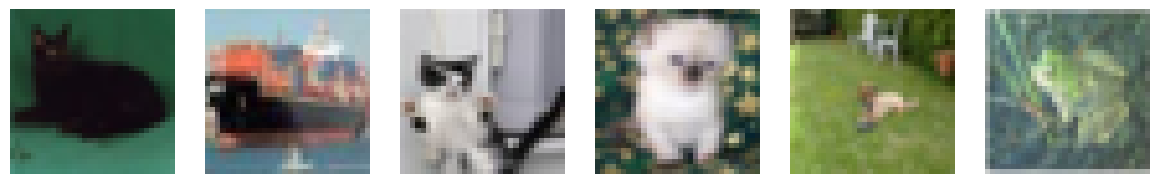

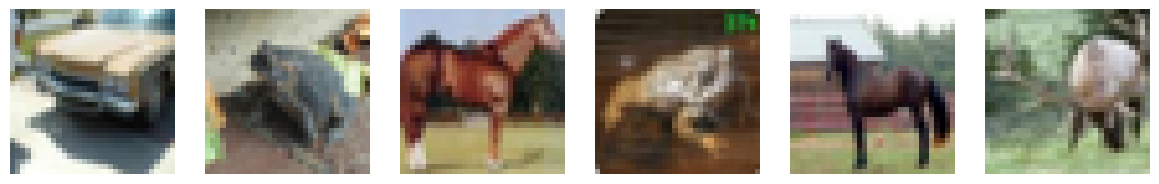

In [2]:
H, W = size, size
# Fixed affine normalization: same convention for both RGB datasets.
image_mean = (0.5, 0.5, 0.5)
image_std = (0.5, 0.5, 0.5)
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(image_mean, image_std),
])
full_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform)
batch_size = 128
analysis_batch_size = 128
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
if train_size == 0 or val_size < analysis_batch_size:
    raise ValueError('Dataset too small for the configured split and analysis sample.')
data_train, data_val = random_split(full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(seed))
train_loader = DataLoader(data_train, batch_size=batch_size, shuffle=False, num_workers=0)
val_loader = DataLoader(data_val, batch_size=analysis_batch_size, shuffle=False, num_workers=0)
train_images, _ = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

# Display only: all calculations use unclipped, normalized RGB tensors.
def display_image(image):
    image = torch.as_tensor(image).detach().cpu().reshape(C, H, W)
    mean = torch.tensor(image_mean).view(C, 1, 1)
    std = torch.tensor(image_std).view(C, 1, 1)
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

for images in (train_images, val_images):
    fig, axes = plt.subplots(1, 6, figsize=(12, 3))
    for i, ax in enumerate(axes):
        ax.imshow(display_image(images[i]))
        ax.axis('off')
    plt.tight_layout()
    plt.show()


In [3]:
class MultiLevelImageTransform(ImageTransform):
    def __init__(self, in_channels, height, width, image_transforms):
        """
        :param image_transforms: list of ImageTransform objects, one for each level of the multi-level transform.
        """
        self.L = len(image_transforms)
        assert image_transforms[0].C == in_channels * 4
        assert image_transforms[0].H == height // 2
        assert image_transforms[0].W == width // 2
        # assert that the image transform dimensions shrink by a factor of 2 at each level, but channels grow by a factor of 2 at each level
        assert all(image_transforms[i].C == image_transforms[i-1].C * 2 for i in range(1, self.L))
        assert all(image_transforms[i].H == image_transforms[i-1].H // 2 for i in range(1, self.L))
        assert all(image_transforms[i].W == image_transforms[i-1].W // 2 for i in range(1, self.L))
        super().__init__(in_channels, height, width)
        self.image_transforms = nn.ModuleList(image_transforms)

        self.squeeze = SqueezeTransform(factor=2)
        

    def forward(self, inputs, context=None):
        batch_size = inputs.shape[0]
        outputs = inputs
        total_logabsdet = inputs.new_zeros(batch_size)
        splits = []
        for i in range(self.L):
            # squeeze
            outputs, log_abs_det = self.squeeze(outputs, None)
            total_logabsdet += log_abs_det

            # flow step
            outputs, log_abs_det = self.image_transforms[i](outputs, None)
            total_logabsdet += log_abs_det

            # split
            split, outputs = torch.chunk(outputs, 2, dim=1)
            splits.append(split)

        # add context if provided
        if context is not None:
            assert context.shape[0] == batch_size
            assert context.shape[1] == self.image_transforms[-1].H
            assert context.shape[2] == self.image_transforms[-1].W
            context_ = torch.zeros_like(outputs)
            context_[:, 0] = context
            outputs = outputs - context_

        # iterate through splits to get outputs in correct order
        for i in reversed(range(self.L)):
            # concatenate split back to outputs
            outputs = torch.cat([splits[i], outputs], dim=1)
            # unsqueeze
            outputs, _ = self.squeeze.inverse(outputs, None)

        return outputs, total_logabsdet
    
    def inverse(self, inputs, context=None):
        # iterate through splits to get outputs in correct order
        outputs = inputs
        splits = []
        for i in range(self.L):
            # squeeze
            outputs, _ = self.squeeze(outputs, None)

            split, outputs = torch.chunk(outputs, 2, dim=1)
            splits.append(split)

        # remove context if provided
        if context is not None:
            assert context.shape[0] == inputs.shape[0]
            assert context.shape[1] == self.image_transforms[-1].H
            assert context.shape[2] == self.image_transforms[-1].W
            context_ = torch.zeros_like(outputs)
            context_[:, 0] = context
            outputs = outputs + context_

        total_logabsdet = inputs.new_zeros(inputs.shape[0])
        for i in reversed(range(self.L)):
            # concatenate
            outputs = torch.cat([splits[i], outputs], dim=1)

            # flow step
            outputs, log_abs_det = self.image_transforms[i].inverse(outputs, None)
            total_logabsdet += log_abs_det

            # unsqueeze
            outputs, log_abs_det = self.squeeze.inverse(outputs, None)
            total_logabsdet += log_abs_det

        return outputs, total_logabsdet

class SimpleMultiLevelImageTransform(MultiLevelImageTransform):
    def __init__(self, in_channels, height, width, kernel_size=3, hidden_channels=64, n_flows=3, n_scales=3):
        super().__init__(in_channels, height, width, [self.create_transform(in_channels * (2 ** i) * 2, height // (2 ** i), width // (2 ** i), kernel_size, hidden_channels, n_flows) for i in range(1, n_scales+1)])

    def create_transform(self, in_channels, height, width, kernel_size, hidden_channels, n_flows):
        transforms_list = []
        # stack n_flows coupling layers with ActNorm in between, using parity to alternate which pixels are transformed
        for i in range(n_flows):
            transforms_list.append(ActNorm(features=in_channels)) # OneByOneConvolution
            transforms_list.append(OneByOneConvolution(in_channels))
            transforms_list.append(Linear2DParityConvImageTransform(in_channels, height, width, kernel_size, parity=i))
            transforms_list.append(Linear2DParityConvImageTransform(in_channels, height, width, kernel_size, parity=i+1))
            transforms_list.append(SimpleTanh2DParityConvImageTransform(in_channels, height, width, hidden_channels=hidden_channels, kernel_size=kernel_size, parity=i))
        transforms_list.append(ActNorm(features=in_channels))
        transforms_list.append(OneByOneConvolution(in_channels))
        transforms_list.append(Linear2DParityConvImageTransform(in_channels, height, width, kernel_size, parity=n_flows))
        transforms_list.append(Linear2DParityConvImageTransform(in_channels, height, width, kernel_size, parity=n_flows+1))
        transform = ImageCompositeTransform(in_channels, height, width, transforms_list)
        return transform

In [4]:
# Defaults from the MNIST transform constructor; edit to match your MNIST YAML.
K = 3
L = 64  # hidden channels
n_flows = 3
n_scales = 3
learning_rate = 1e-3
if n_scales < 1 or H % (2 ** n_scales) or W % (2 ** n_scales):
    raise ValueError("H and W must be divisible by 2**n_scales, with n_scales >= 1")

model = Flow(
    transform=SimpleMultiLevelImageTransform(
        in_channels=C, height=H, width=W, kernel_size=K,
        hidden_channels=L, n_flows=n_flows, n_scales=n_scales),
    distribution=StandardNormal(shape=[C, H, W]),
).to(device)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Use real training data for ActNorm initialization, not random synthetic inputs.
model.train()
with torch.no_grad():
    probe = train_images[:8].to(device)
    latent, forward_logdet = model._transform(probe)
    reconstructed, inverse_logdet = model._transform.inverse(latent)
    assert latent.shape == probe.shape
    assert forward_logdet.shape == (len(probe),)
    assert torch.isfinite(latent).all() and torch.isfinite(forward_logdet).all()
    torch.testing.assert_close(reconstructed, probe, atol=1e-4, rtol=1e-4)
    torch.testing.assert_close(
        forward_logdet + inverse_logdet, torch.zeros_like(forward_logdet),
        atol=1e-2, rtol=0)
    assert torch.isfinite(model.log_prob(probe)).all()
    print("Scale shapes:", [(C * 2**(i+1), H // 2**i, W // 2**i)
                            for i in range(1, n_scales + 1)])
    print("Inverse max absolute error:", (reconstructed - probe).abs().max().item())


Scale shapes: [(12, 16, 16), (24, 8, 8), (48, 4, 4)]
Inverse max absolute error: 2.3245811462402344e-06


/Users/wdiepeveen/Documents/Postdoc/projects/2 - Riemannian geometry-based fairness in data science/src/iso-Riemannian-geometry/.venv/lib/python3.13/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2279.)
  outputs, _ = torch.triangular_solve(


In [5]:
# Generate samples
@torch.no_grad()
def generate_samples(model, n_samples):
    samples = model.sample(n_samples).cpu()
    return samples

In [6]:
# Same likelihood objective and training-loss checkpoint selection as the source.
def train(phi, train_loader, optimizer, n_epochs, save_dir='results', start_epoch=0,
          best_loss=float('inf')):
    os.makedirs(save_dir, exist_ok=True)
    for epoch in range(start_epoch, n_epochs):
        phi.train()
        total_loss, count = 0.0, 0
        for x, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{n_epochs}"):
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = -phi.nflow.log_prob(x).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
            count += len(x)
        avg_epoch_loss = total_loss / count
        improved = avg_epoch_loss < best_loss
        best_loss = min(best_loss, avg_epoch_loss)
        checkpoint = {
            'epoch': epoch, 'model_state_dict': phi.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': avg_epoch_loss, 'best_loss': best_loss,
            'torch_rng_state': torch.get_rng_state(),
        }
        if torch.cuda.is_available():
            checkpoint['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
        torch.save(checkpoint, os.path.join(save_dir, 'last_model.pth'))
        if (epoch + 1) % 25 == 0:
            torch.save(checkpoint, os.path.join(save_dir, f'epoch_{epoch+1}_model.pth'))
        if improved:
            torch.save(checkpoint, os.path.join(save_dir, 'best_model.pth'))
        print(f"Epoch {epoch+1}: NLL/image={avg_epoch_loss:.4f}; best={best_loss:.4f}")


In [7]:
n_epochs = 100
phi = NFlowImageDiffeomorphism(C, H, W, model)
checkpoint_dir = os.path.join(results_folder,
    f"checkpoints_hidden={L}_kernel={K}_flows={n_flows}_scales={n_scales}_lr={learning_rate}")
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = os.path.join(checkpoint_dir, 'best_model.pth')
if train_model:
    start_epoch, best_loss = 0, float('inf')
    last_path = os.path.join(checkpoint_dir, 'last_model.pth')
    if resume_training and os.path.isfile(last_path):
        checkpoint = torch.load(last_path, map_location=device, weights_only=True)
        phi.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_loss = checkpoint['best_loss']
        torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
        if torch.cuda.is_available() and 'cuda_rng_state_all' in checkpoint:
            torch.cuda.set_rng_state_all([s.cpu() for s in checkpoint['cuda_rng_state_all']])
    train(phi, train_loader, optimizer, n_epochs, checkpoint_dir, start_epoch, best_loss)
if not os.path.isfile(best_model_path):
    raise FileNotFoundError('No best checkpoint. Set train_model=True to train first.')
checkpoint = torch.load(best_model_path, map_location=device, weights_only=True)
phi.load_state_dict(checkpoint['model_state_dict'])
phi.eval()


Epoch 1/100: 100%|██████████| 313/313 [03:06<00:00,  1.68it/s]


Epoch 1: NLL/image=-2690.9886; best=-2690.9886


Epoch 2/100:   1%|          | 2/313 [00:01<04:41,  1.11it/s]


KeyboardInterrupt: 

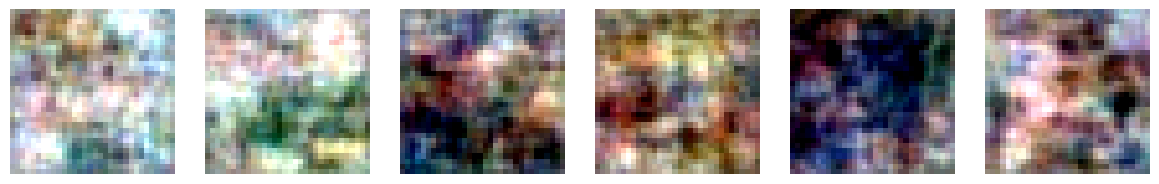

In [8]:
# Visualize generated samples
samples = generate_samples(phi.nflow, 100).reshape(-1, C, H, W)

# Plot the first 6 images
fig, axes = plt.subplots(1, 6, figsize=(12, 8))
axes = axes.flatten()

for i in range(6):
    axes[i].imshow(display_image(samples[i].squeeze()))
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [9]:
# special points
num_points = 10
num_geodesics = 5

x0 = val_images[0:2*num_geodesics:2].to(device)
x1 = val_images[1:2*num_geodesics+1:2].to(device)

### Naive Riemannian data analysis ###

In [10]:
# Construct pullback manifold
manifold = StandardPullbackImageEuclidean(phi)

In [11]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    geodesics[i] = manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

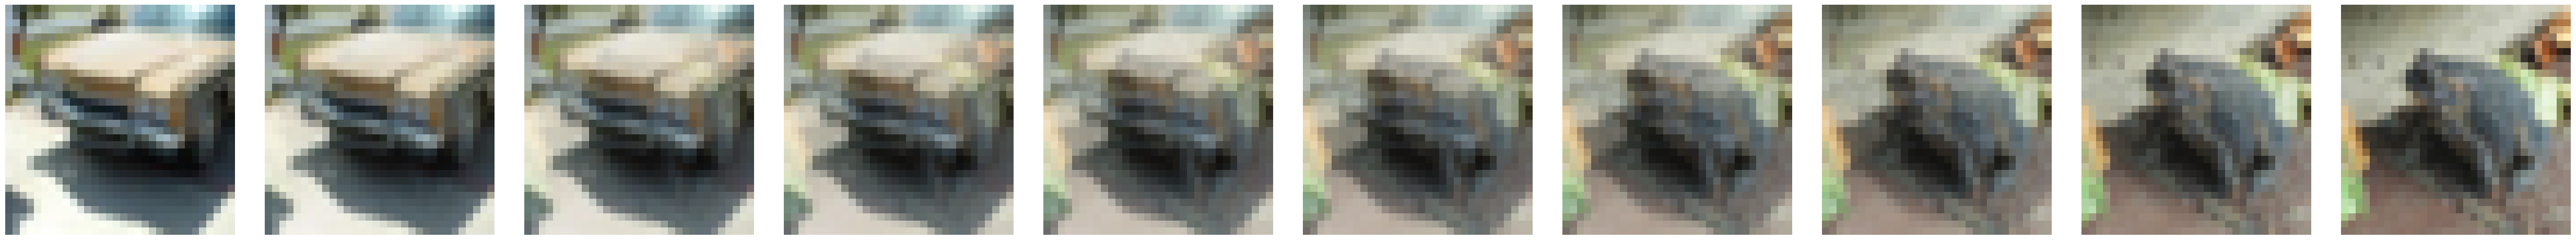

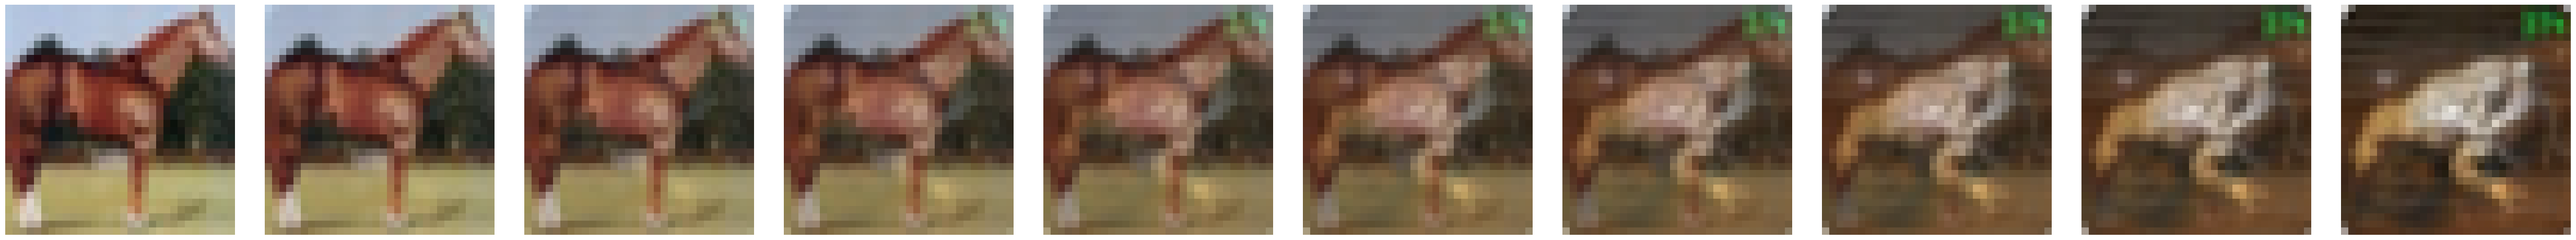

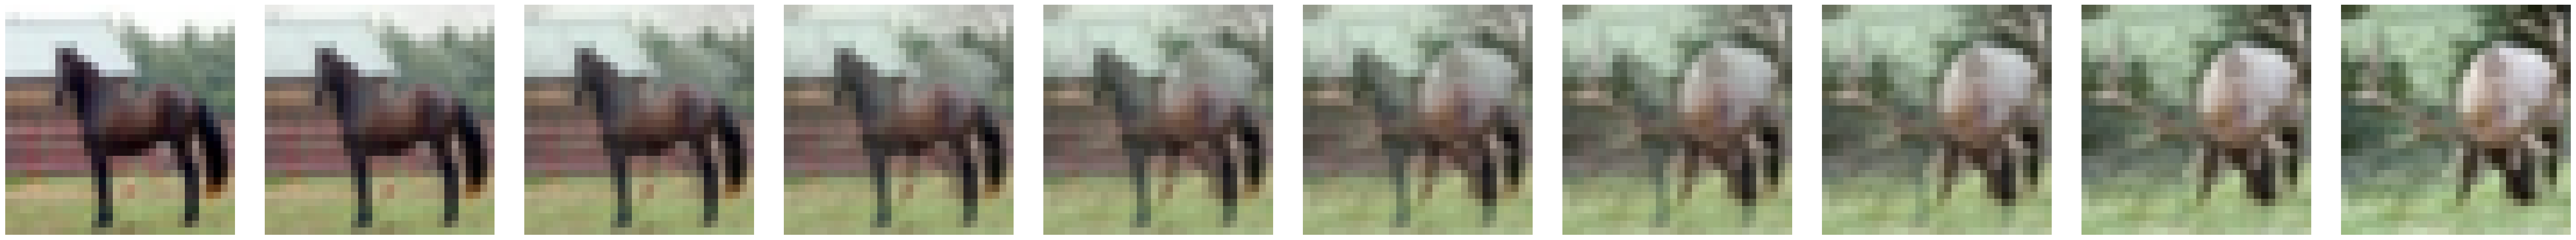

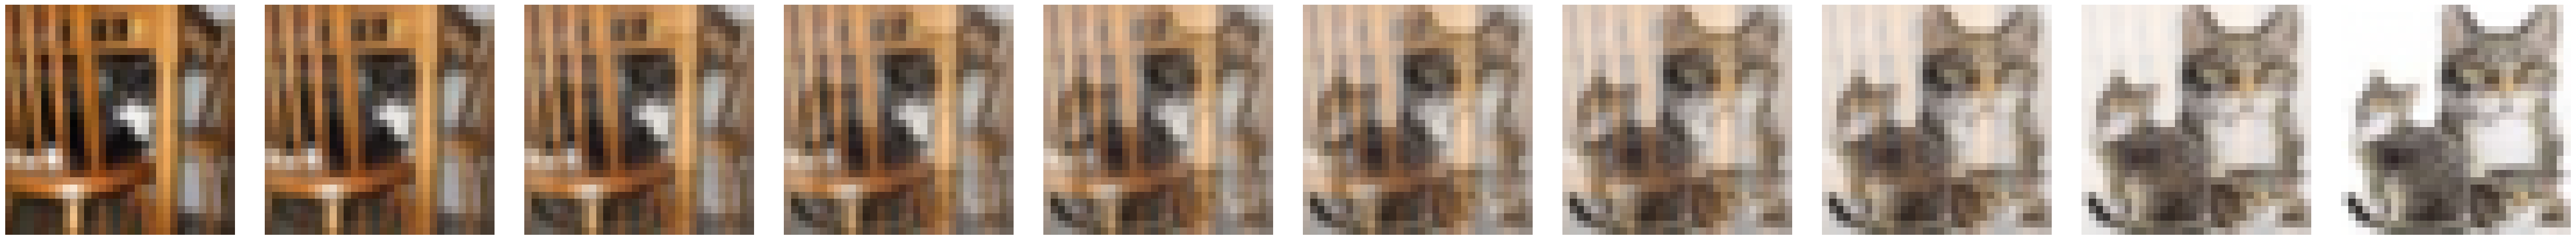

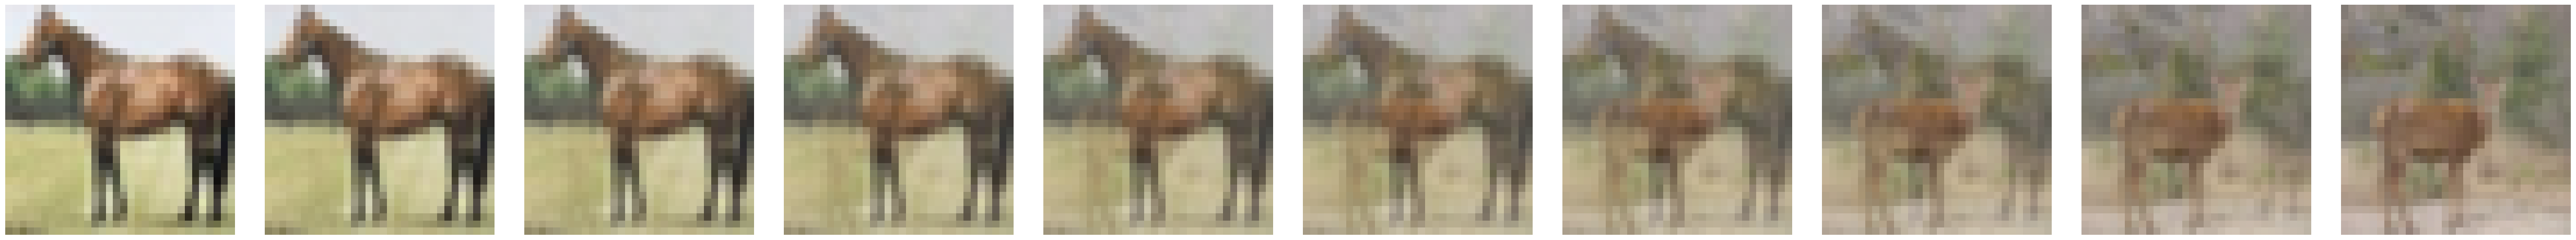

In [12]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1,num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"geodesic-{i}.eps"))
    plt.show()

In [13]:
# Compute barycentre
bary = manifold.barycentre(val_images.to(device)).detach().cpu()

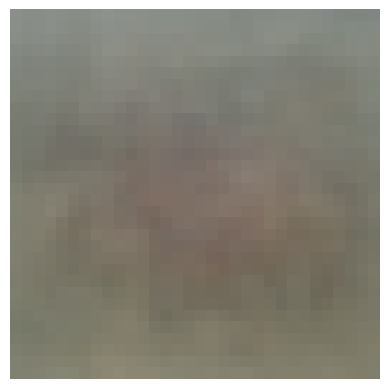

In [14]:
# Plot barycentres
plt.imshow(display_image(bary.squeeze()))
plt.axis('off')
plt.show()

In [15]:
# Construct curvature corrected l2-pga solver
l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), manifold, bary.to(device))

In [16]:
# Compute low rank approximations
Xi_bary, exp_bary_Xi, _ = l2_pga_solver.solve(20)

Computing rank 20 approximation on tangent space
Computing rank 20 approximation on euclidean space
Computing rank 20 errors for data point 1/128
Computing rank 20 errors for data point 2/128
Computing rank 20 errors for data point 3/128
Computing rank 20 errors for data point 4/128
Computing rank 20 errors for data point 5/128
Computing rank 20 errors for data point 6/128
Computing rank 20 errors for data point 7/128
Computing rank 20 errors for data point 8/128
Computing rank 20 errors for data point 9/128
Computing rank 20 errors for data point 10/128
Computing rank 20 errors for data point 11/128
Computing rank 20 errors for data point 12/128
Computing rank 20 errors for data point 13/128
Computing rank 20 errors for data point 14/128
Computing rank 20 errors for data point 15/128
Computing rank 20 errors for data point 16/128
Computing rank 20 errors for data point 17/128
Computing rank 20 errors for data point 18/128
Computing rank 20 errors for data point 19/128
Computing rank 2

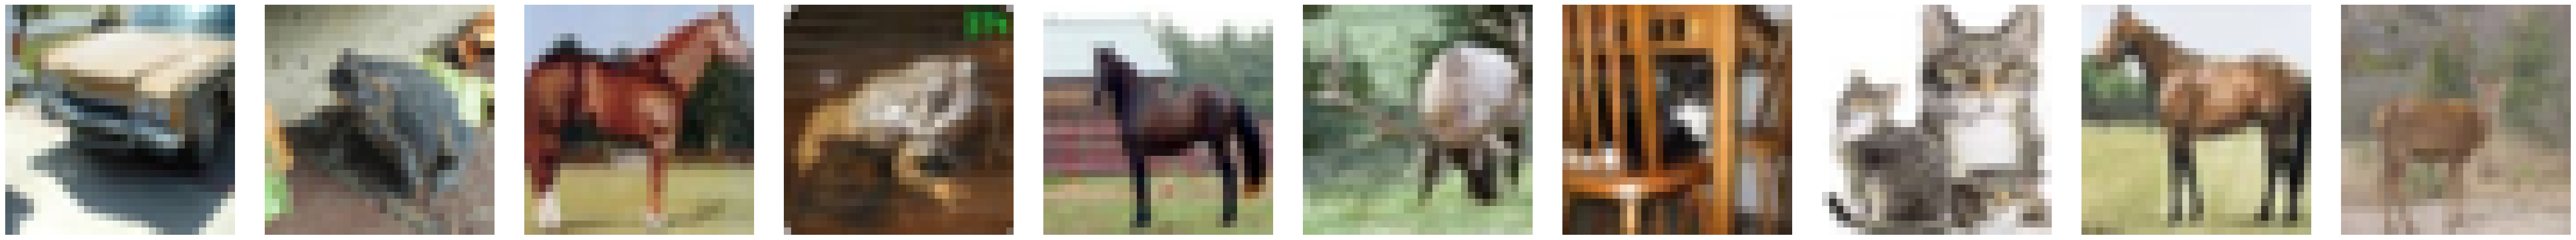

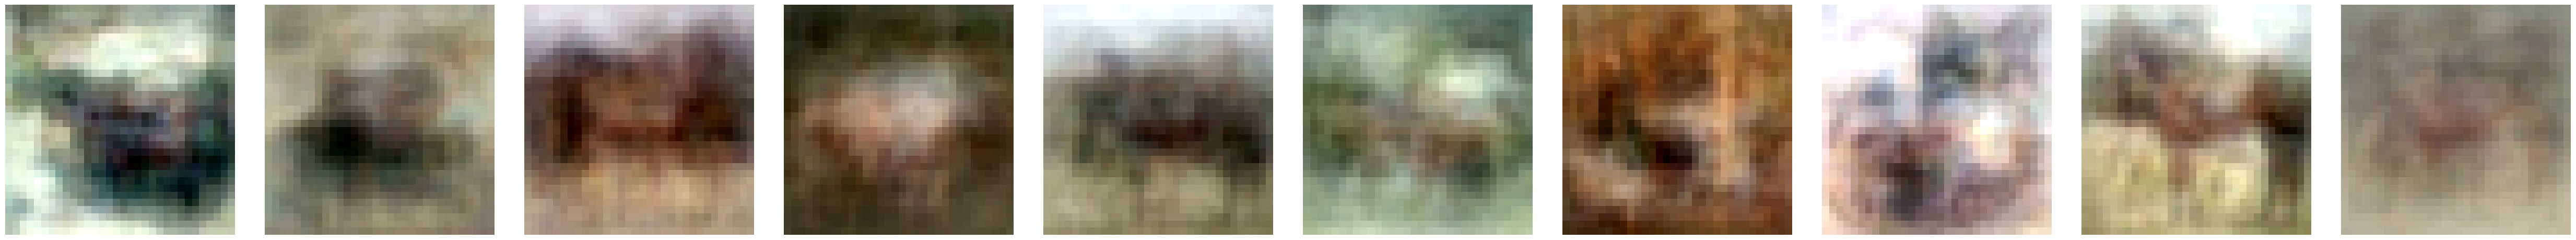

In [17]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"val-l2-pga.eps"))
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pga.eps"))
plt.show()

### Isometrized Riemannian data analysis ###

In [ ]:
# Construct isometrized pullback manifold
num_intervals = 5  # You can adjust this value as needed
iso_manifold = l2IsometrizedImageEuclidean(manifold, num_intervals=num_intervals)

In [ ]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

iso_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    iso_geodesics[i] = iso_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

In [ ]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(iso_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"iso-geodesic-{i}-M{num_intervals}.eps"))
    plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
iso_l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), iso_manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
iso_Xi_bary, iso_exp_bary_Xi, _ = iso_l2_pga_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(iso_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,f"iso-l2-pga-M{num_intervals}.eps"))
plt.show()

### l2 data analysis ###

In [18]:
# Construct manifold
l2_manifold = StandardImageEuclidean(C, H, W)

In [19]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

l2_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    l2_geodesics[i] = l2_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

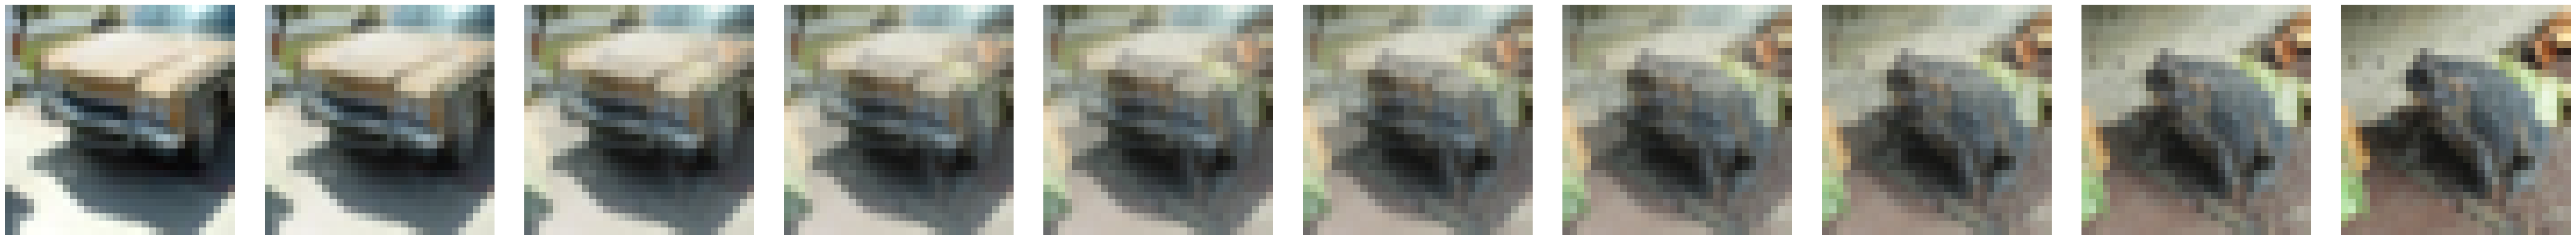

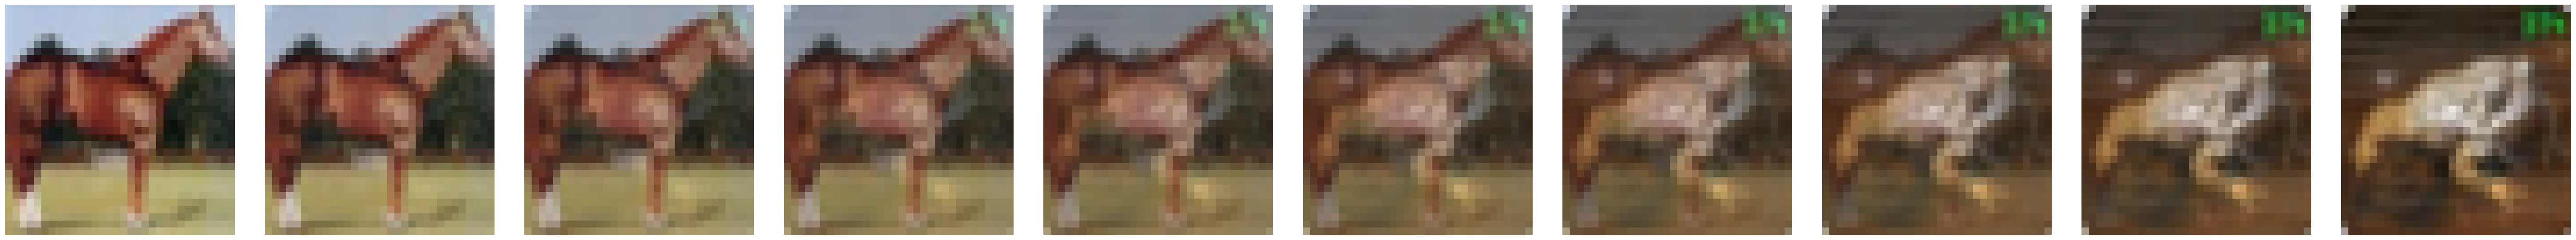

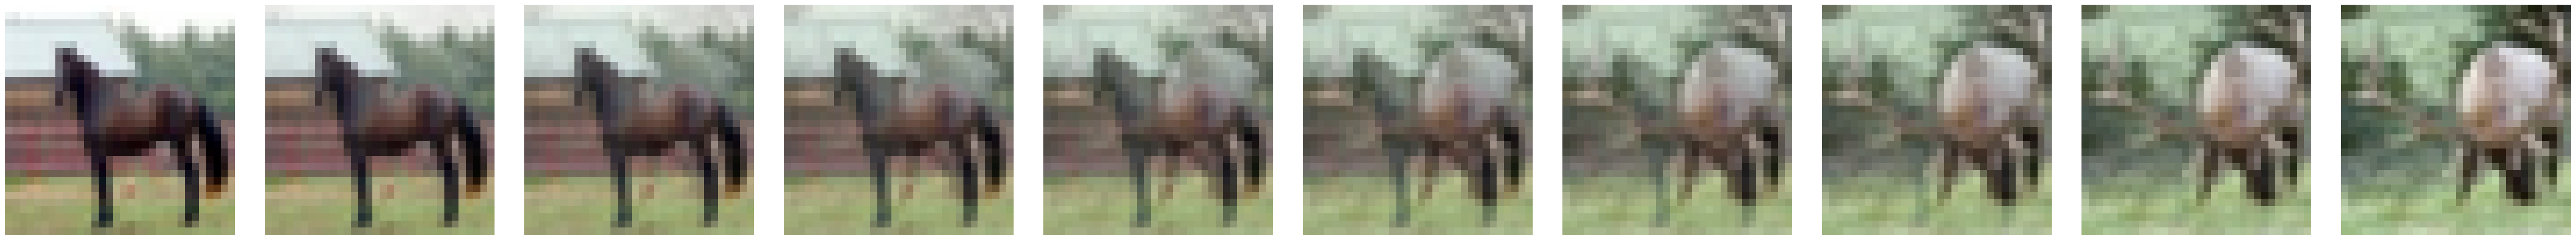

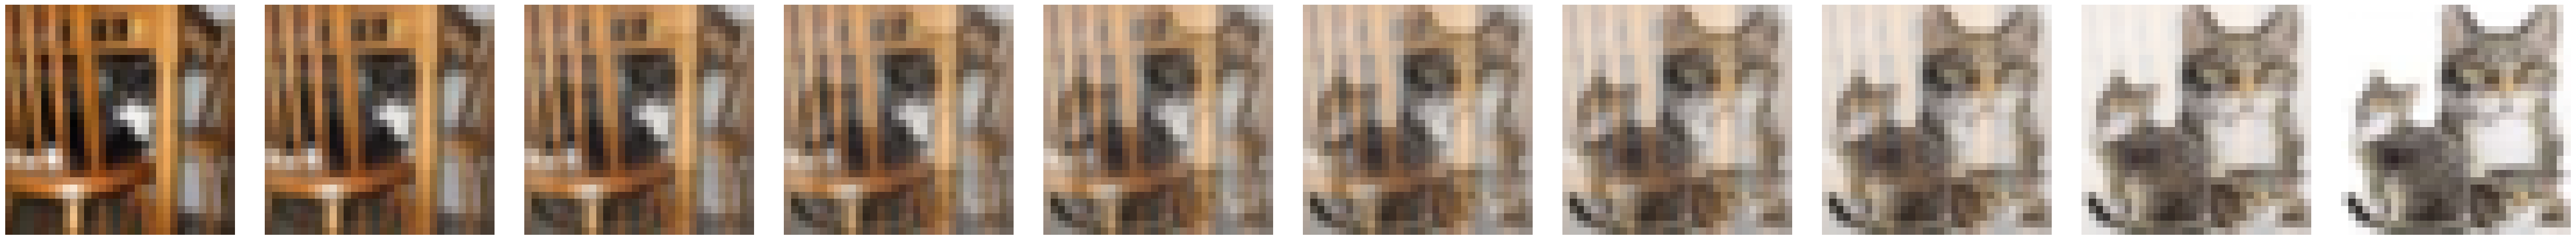

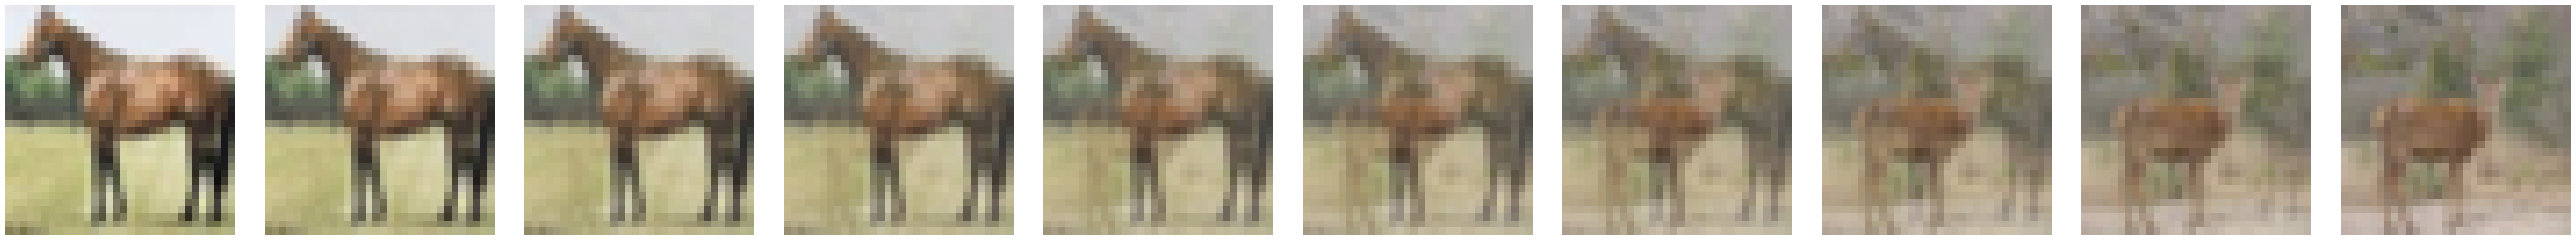

In [20]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(l2_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"l2-geodesic-{i}.eps"))
    plt.show()

In [21]:
# Construct curvature corrected l2-pga solver
l2_pca_solver = l2TangentSpacePCAImageSolver(val_images.to(device), l2_manifold, bary.to(device))

In [22]:
# Compute low rank approximations
l2_Xi_bary, l2_exp_bary_Xi, _ = l2_pca_solver.solve(20)

Computing rank 20 approximation on tangent space
Computing rank 20 approximation on euclidean space
Computing rank 20 errors for data point 1/128
Computing rank 20 errors for data point 2/128
Computing rank 20 errors for data point 3/128
Computing rank 20 errors for data point 4/128
Computing rank 20 errors for data point 5/128
Computing rank 20 errors for data point 6/128
Computing rank 20 errors for data point 7/128
Computing rank 20 errors for data point 8/128
Computing rank 20 errors for data point 9/128
Computing rank 20 errors for data point 10/128
Computing rank 20 errors for data point 11/128
Computing rank 20 errors for data point 12/128
Computing rank 20 errors for data point 13/128
Computing rank 20 errors for data point 14/128
Computing rank 20 errors for data point 15/128
Computing rank 20 errors for data point 16/128
Computing rank 20 errors for data point 17/128
Computing rank 20 errors for data point 18/128
Computing rank 20 errors for data point 19/128
Computing rank 2

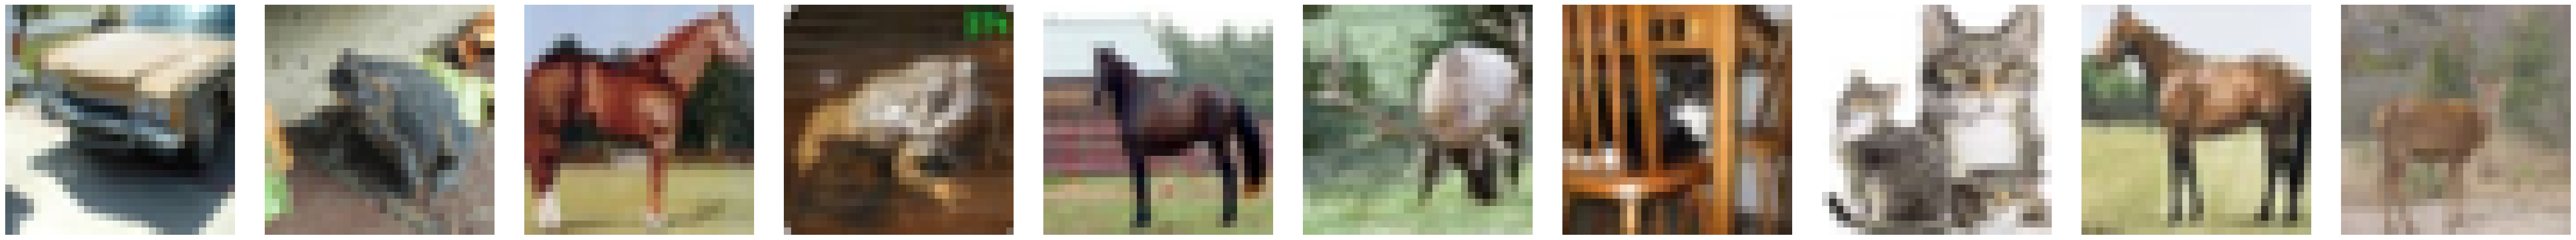

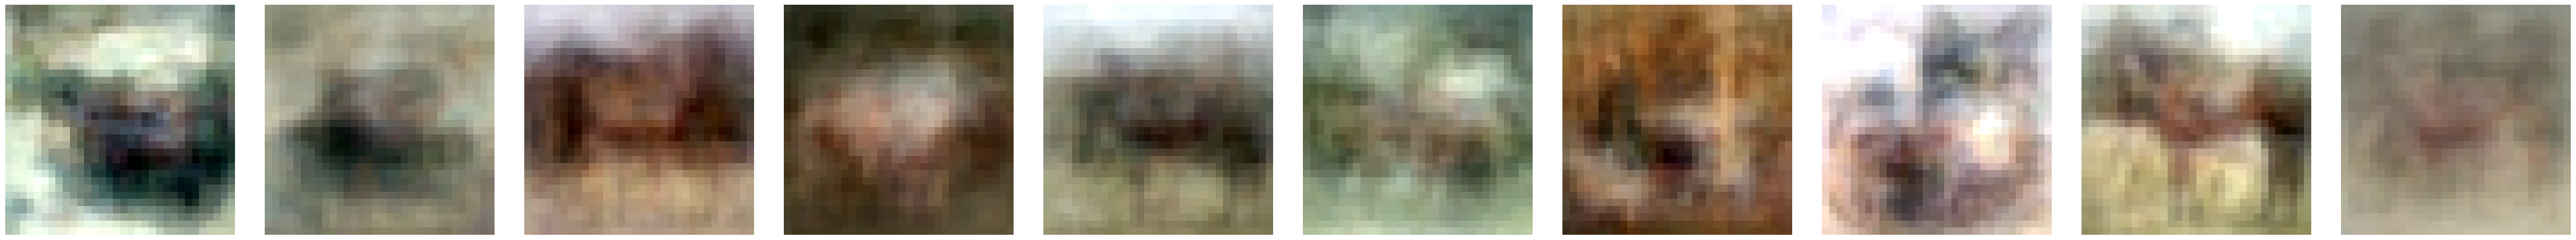

In [23]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(l2_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pca.eps"))
plt.show()

### Comparing naive and isometrized ###

In [24]:
# Compute geodesic relative rmse from the barycentre
squared_geo_errors = torch.zeros(len(val_images))
dists = ((val_images - bary)**2).sum([1,2,3])
for i, x_i in enumerate(val_images):
    geodesic_i = manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    iso_geodesic_i = iso_manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    squared_geo_errors[i] = ((geodesic_i - iso_geodesic_i)**2).mean(0).sum()

geo_rel_rmse = (squared_geo_errors.mean() / dists.mean()).sqrt()
print(geo_rel_rmse)

NameError: name 'iso_manifold' is not defined

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_geo_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('geodesic error')
plt.savefig(os.path.join(results_folder,f"geo-error-M{num_intervals}.eps"))
plt.show()

In [ ]:
# Compute low rank relative rmse from the barycentre
squared_low_rank_errors = ((val_images - exp_bary_Xi.cpu())**2).sum([1,2,3])
low_rank_rel_rmse = (squared_low_rank_errors.mean() / dists.mean()).sqrt()

squared_low_rank_iso_errors = ((val_images - iso_exp_bary_Xi.cpu())**2).sum([1,2,3])
iso_low_rank_rel_rmse = (squared_low_rank_iso_errors.mean() / dists.mean()).sqrt()

squared_low_rank_l2_errors = ((val_images - l2_exp_bary_Xi.cpu())**2).sum([1,2,3])
l2_low_rank_rel_rmse = (squared_low_rank_l2_errors.mean() / dists.mean()).sqrt()

print(low_rank_rel_rmse)
print(iso_low_rank_rel_rmse)
print(l2_low_rank_rel_rmse)

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_low_rank_errors.sqrt() - squared_low_rank_iso_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('low-rank error')
plt.savefig(os.path.join(results_folder,f"low-rank-error-M{num_intervals}.eps"))
plt.show()